# Validade Temporal e Supersessão de Fatos em Memória Associativa Hebbiana (HeLa-Mem)
## Notebook 02 — Proposta B, Ablação B0 e Análise dos Resultados

**Projeto de Mestrado — Deep Learning (CIn / UFPE)**
**Autor:** Filipe Augusto de Ataíde Barbosa (`faab@cin.ufpe.br`)
**Artigo-Base:** *HeLa-Mem: Hebbian Learning and Associative Memory for LLM Agents* (ACL 2026, commit `68f19b3`)
**Dados:** 500 questões do *LongMemEval* no arquivo distribuído com o HeLa-Mem (apenas sessões de evidência; ver Notebook 01, Seção 4)

---

### Passo a passo

| Passo | Conteúdo | Precisa de API? |
|---|---|---|
| 0 | Ambiente e dados | não |
| 1 | Execução dos pipelines (B, B0, B') | **sim** (opcional) |
| 2 | Carga dos resultados versionados | não |
| 3 | Baseline A vs. Proposta B | não |
| 4 | Evolução dos resultados ao longo do projeto | não |
| 5 | Ablação B0: decomposição do ganho | não |
| 6 | Estatística: McNemar, IC 95% e Holm | não |
| 7 | Estrutura dos grafos temporais | não |
| 8 | Análise qualitativa: casos e regressões | não |
| 9 | Figuras do artigo | não |
| 10 | Auditoria do processo | não |
| 11 | Conclusões | — |

As condições comparadas são:
- **A** — HeLa-Mem original (Notebook 01).
- **B0** — mesmos fatos extraídos por sessão que B, **sem** o mecanismo temporal (todos os fatos ativos, $\mathcal{V} \equiv 1$, sem arestas do classificador, prompt original).
- **B** — Proposta completa: validade $[t_{start}, t_{end}]$, supersessão, $\mathcal{V}(f_i, t_{query})$ e tags de estado no prompt.

A$\rightarrow$B0 mede o efeito da extração por sessão; B0$\rightarrow$B mede o efeito do mecanismo temporal.

## Passo 0 — Ambiente e Dados

Funciona localmente ou no Google Colab. Os resultados já estão versionados (`results/*.zip` e `eval_summary.json`), então **toda a análise roda sem chave de API**. A chave só é necessária para reexecutar os pipelines no Passo 1.

No Colab, para o Passo 1, adicione `OPENAI_API_KEY` em **Secrets** (ícone de chave).

In [1]:
import os
import sys
import json
import subprocess
import zipfile
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    if not Path("/content/mestrado-dl-projeto").exists():
        subprocess.run(["git", "clone", "--recurse-submodules",
                        "https://github.com/ataidefilipe/mestrado-dl-projeto.git", "/content/mestrado-dl-projeto"], check=True)
    ROOT = Path("/content/mestrado-dl-projeto")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "sentence-transformers", "openai", "python-dotenv"], check=True)
    try:
        from google.colab import userdata
        os.environ["OPENAI_API_KEY"] = userdata.get("OPENAI_API_KEY") or ""
    except Exception:
        pass
else:
    here = Path.cwd().resolve()
    ROOT = here.parent if here.name == "notebooks" else here

os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT / "external" / "HeLa-Mem"))
sys.path.insert(0, str(ROOT / "src" / "analysis"))

from dotenv import load_dotenv
load_dotenv(ROOT / ".env")
HAS_KEY = bool(os.environ.get("OPENAI_API_KEY"))

RES = ROOT / "results"
A_DIR = RES / "longmemeval_baseline_full"
B_DIR = RES / "longmemeval_temporal_full"
DATA_PATH = ROOT / "external" / "HeLa-Mem" / "data" / "longmemeval_s.json"

def unzip_once(zip_path, dest, marker):
    # Descompacta sem sobrescrever, só se o arquivo-marcador ainda não existir
    if not (dest / marker).exists():
        dest.mkdir(parents=True, exist_ok=True)
        with zipfile.ZipFile(zip_path) as z:
            for member in z.namelist():
                if not (dest / member).exists():
                    z.extract(member, dest)

unzip_once(RES / "baseline_episodic_500.zip", A_DIR, "001be529_hebbian.json")
unzip_once(RES / "temporal_encoded_500.zip", B_DIR, "001be529_long_term_kb_graph.json")

print(f"Projeto: {ROOT.name}")
print(f"Dados: {DATA_PATH.exists()} | grafos de A: {(A_DIR / '001be529_hebbian.json').exists()} | grafos de B: {(B_DIR / '001be529_long_term_kb_graph.json').exists()}")
print(f"Chave de API disponível: {'sim' if HAS_KEY else 'não (análise roda normalmente; Passo 1 fica desativado)'}")

Projeto: mestrado-dl-projeto
Dados: True | grafos de A: True | grafos de B: True
Chave de API disponível: não (análise roda normalmente; Passo 1 fica desativado)


## Passo 1 — Execução dos Pipelines (opcional)

Os resultados já estão versionados; **não é preciso reexecutar** para reproduzir a análise. As flags abaixo permitem regenerar cada condição:

- **B** — codificação semântica temporal (reutiliza os grafos episódicos de A) e avaliação. Com os 500 itens já codificados, o runner pula as etapas concluídas (checkpoint por item).
- **B0** — reavalia os fatos de B sem o mecanismo temporal (`--ablation no_temporal`); não refaz a extração.
- **B'** — reavalia B numa pasta separada, para medir o ruído entre execuções (geração e juiz usam `temperature=0.7`).

Cada execução de avaliação faz cerca de 1.500 chamadas ao `gpt-4o-mini`.

In [2]:
RUN_B = False        # codificação + avaliação da Proposta B
RUN_B0 = False       # ablação B0 (só avaliação)
RUN_B_RERUN = False  # B' para medir ruído (só avaliação)
WORKERS = 5

runner = ["python", "-u", "src/analysis/run_temporal_hela_longmemeval.py", "--num_items", "500",
          "--output_dir", str(B_DIR), "--reuse_episodic_dir", str(A_DIR), "--workers", str(WORKERS)]

jobs = []
if RUN_B:
    jobs.append(runner + ["--stage", "all"])
if RUN_B0:
    jobs.append(runner + ["--stage", "eval", "--ablation", "no_temporal", "--results_subdir", "eval_results_b0"])
if RUN_B_RERUN:
    jobs.append(runner + ["--stage", "eval", "--results_subdir", "eval_results_b_rerun"])

if jobs and not HAS_KEY:
    print("OPENAI_API_KEY ausente: execuções desativadas.")
elif not jobs:
    print("Nenhuma execução solicitada; a análise usa os resultados versionados.")
else:
    for cmd in jobs:
        print(">>>", " ".join(cmd[3:]))
        subprocess.run(cmd, check=True, cwd=ROOT)

Nenhuma execução solicitada; a análise usa os resultados versionados.


## Passo 2 — Carga dos Resultados

Carregamos os resumos de A, B0 e B (e B', se existir) e os metadados do dataset.

In [3]:
import numpy as np
import pandas as pd
from compare_ablation import load_correct, mcnemar_exact, supersession_ids

pd.set_option("display.max_colwidth", 120)

def load_summary(path):
    with open(path, encoding="utf-8") as f:
        return json.load(f)

paths = {
    "A": A_DIR / "eval_results" / "eval_summary.json",
    "B0": B_DIR / "eval_results_b0" / "eval_summary.json",
    "B": B_DIR / "eval_results" / "eval_summary.json",
    "B'": B_DIR / "eval_results_b_rerun" / "eval_summary.json",
}
summaries = {k: load_summary(p) for k, p in paths.items() if p.exists()}
correct = {k: {r["question_id"]: int(r["correct"]) for r in s["results"]} for k, s in summaries.items()}
answers = {k: {r["question_id"]: r.get("generated_answer", "") for r in s["results"]} for k, s in summaries.items()}

with open(DATA_PATH, encoding="utf-8") as f:
    dataset = {d["question_id"]: d for d in json.load(f)}
qtype = {q: d["question_type"] for q, d in dataset.items()}
ids = sorted(set.intersection(*[set(v) for v in correct.values()]))

TYPES = ["knowledge-update", "temporal-reasoning", "multi-session",
         "single-session-preference", "single-session-assistant", "single-session-user"]

print("Condições carregadas:", ", ".join(f"{k} ({sum(v.values())}/{len(v)})" for k, v in correct.items()))
print("Questões pareadas:", len(ids))

Condições carregadas: A (306/500), B0 (321/500), B (328/500)
Questões pareadas: 500


## Passo 3 — Baseline A vs. Proposta B

Acurácia por categoria e transições pareadas (ganhos $0 \rightarrow 1$ e regressões $1 \rightarrow 0$).

In [4]:
def acc_table(conds):
    rows = []
    for t in TYPES + ["OVERALL"]:
        sub = ids if t == "OVERALL" else [q for q in ids if qtype[q] == t]
        row = {"Categoria": t, "N": len(sub)}
        for c in conds:
            k = sum(correct[c][q] for q in sub)
            row[c] = f"{k} ({100 * k / len(sub):.2f}%)"
        rows.append(row)
    return pd.DataFrame(rows)

def transitions(x, y, sub):
    g = sum(correct[x][q] == 0 and correct[y][q] == 1 for q in sub)
    r = sum(correct[x][q] == 1 and correct[y][q] == 0 for q in sub)
    return g, r

display(acc_table(["A", "B"]))

rows = []
for t in TYPES + ["OVERALL"]:
    sub = ids if t == "OVERALL" else [q for q in ids if qtype[q] == t]
    g, r = transitions("A", "B", sub)
    rows.append({"Categoria": t, "Ganhos": g, "Regressões": r, "Saldo": g - r})
display(pd.DataFrame(rows))

,Categoria,N,A,B
0,knowledge-update,78,57 (73.08%),65 (83.33%)
1,temporal-reasoning,133,69 (51.88%),74 (55.64%)
2,multi-session,133,62 (46.62%),65 (48.87%)
3,single-session-preference,30,8 (26.67%),14 (46.67%)
4,single-session-assistant,56,49 (87.50%),52 (92.86%)
5,single-session-user,70,61 (87.14%),58 (82.86%)
6,OVERALL,500,306 (61.20%),328 (65.60%)


,Categoria,Ganhos,Regressões,Saldo
0,knowledge-update,11,3,8
1,temporal-reasoning,15,10,5
2,multi-session,14,11,3
3,single-session-preference,8,2,6
4,single-session-assistant,3,0,3
5,single-session-user,3,6,-3
6,OVERALL,54,32,22


## Passo 4 — Evolução dos Resultados

A Proposta B teve duas rodadas completas. Na primeira (commit `d279613`, 64,60%), 99 questões, nas posições 100–199 do arquivo, ficaram com o grafo semântico vazio por falha de execução. Elas foram recodificadas com um critério objetivo (grafo vazio), independente de acerto. A tabela mostra a trajetória completa.

In [5]:
def old_b_summary():
    try:
        raw = subprocess.run(["git", "show", "d279613:results/longmemeval_temporal_full/eval_results/eval_summary.json"],
                             cwd=ROOT, capture_output=True, check=True).stdout.decode("utf-8")
        return {r["question_id"]: int(r["correct"]) for r in json.loads(raw)["results"]}
    except Exception as e:
        print("Histórico git indisponível:", e)
        return None

old_b = old_b_summary()
ku = [q for q in ids if qtype[q] == "knowledge-update"]

evo = [("Entrega 1: reprodução de A", correct["A"])]
if old_b:
    evo.append(("B, 1ª rodada (99 grafos semânticos vazios)", old_b))
evo.append(("B, após recodificar os itens 100–199", correct["B"]))
if "B0" in correct:
    evo.append(("B0: mesmos fatos de B, sem mecanismo temporal", correct["B0"]))
if "B'" in correct:
    evo.append(("B': repetição de B (ruído)", correct["B'"]))

display(pd.DataFrame([{
    "Marco": name,
    "Global": f"{100 * sum(d[q] for q in ids) / len(ids):.2f}%",
    "Knowledge Update": f"{sum(d[q] for q in ku)}/{len(ku)}",
} for name, d in evo]))

if old_b:
    changed = [q for q in ids if old_b[q] != correct["B"][q]]
    with zipfile.ZipFile(RES / "temporal_encoded_500.zip") as z:
        recoded = {i.filename.replace("_long_term_kb_graph.json", "") for i in z.infolist()
                   if i.filename.endswith("_long_term_kb_graph.json") and i.date_time[:3] == (2026, 11, 3)}
    outside = [q for q in changed if q not in recoded]
    print(f"Questões recodificadas na 2ª rodada: {len(recoded)}")
    print(f"Questões que mudaram de resultado entre as rodadas: {len(changed)} "
          f"(fora do lote recodificado: {len(outside)})")

,Marco,Global,Knowledge Update
0,Entrega 1: reprodução de A,61.20%,57/78
1,"B, 1ª rodada (99 grafos semânticos vazios)",64.60%,57/78
2,"B, após recodificar os itens 100–199",65.60%,65/78
3,"B0: mesmos fatos de B, sem mecanismo temporal",64.20%,51/78


Questões recodificadas na 2ª rodada: 100
Questões que mudaram de resultado entre as rodadas: 21 (fora do lote recodificado: 0)


## Passo 5 — Ablação B0: Decomposição do Ganho

De A para B mudaram duas coisas ao mesmo tempo: o modo de extrair fatos (blocos de 10 turnos $\rightarrow$ por sessão) e o mecanismo temporal. A B0 separa os dois efeitos.

In [6]:
if "B0" not in correct:
    print("Resultados da B0 não encontrados. Rode o Passo 1 com RUN_B0 = True.")
else:
    display(acc_table(["A", "B0", "B"]))

    rows = []
    for t in TYPES + ["OVERALL"]:
        sub = ids if t == "OVERALL" else [q for q in ids if qtype[q] == t]
        row = {"Categoria": t}
        for x, y in (("A", "B0"), ("B0", "B"), ("A", "B")):
            g, r = transitions(x, y, sub)
            row[f"{x}→{y}"] = f"{g - r:+d} (+{g}/−{r})"
        rows.append(row)
    print("Saldo líquido (ganhos/regressões) por etapa:")
    display(pd.DataFrame(rows))

,Categoria,N,A,B0,B
0,knowledge-update,78,57 (73.08%),51 (65.38%),65 (83.33%)
1,temporal-reasoning,133,69 (51.88%),76 (57.14%),74 (55.64%)
2,multi-session,133,62 (46.62%),72 (54.14%),65 (48.87%)
3,single-session-preference,30,8 (26.67%),12 (40.00%),14 (46.67%)
4,single-session-assistant,56,49 (87.50%),50 (89.29%),52 (92.86%)
5,single-session-user,70,61 (87.14%),60 (85.71%),58 (82.86%)
6,OVERALL,500,306 (61.20%),321 (64.20%),328 (65.60%)


Saldo líquido (ganhos/regressões) por etapa:


,Categoria,A→B0,B0→B,A→B
0,knowledge-update,-6 (+5/−11),+14 (+14/−0),+8 (+11/−3)
1,temporal-reasoning,+7 (+16/−9),-2 (+8/−10),+5 (+15/−10)
2,multi-session,+10 (+16/−6),-7 (+7/−14),+3 (+14/−11)
3,single-session-preference,+4 (+6/−2),+2 (+3/−1),+6 (+8/−2)
4,single-session-assistant,+1 (+2/−1),+2 (+2/−0),+3 (+3/−0)
5,single-session-user,-1 (+2/−3),-2 (+1/−3),-3 (+3/−6)
6,OVERALL,+15 (+47/−32),+7 (+35/−28),+22 (+54/−32)


## Passo 6 — Estatística

- **McNemar exato** sobre os pares discordantes de cada comparação (bilateral).
- **IC 95%** da diferença de acurácia pareada (Wald pareado).
- **Correção de Holm** sobre as 12 comparações por categoria (6 categorias × 2 etapas), para controlar falsos positivos.

Os testes tratam cada execução como determinística; a comparação B vs. B' (quando disponível) dá a referência de ruído.

In [7]:
def paired_ci(g, r, n):
    d = (g - r) / n
    se = np.sqrt(g + r - (g - r) ** 2 / n) / n
    return 100 * d, 100 * (d - 1.96 * se), 100 * (d + 1.96 * se)

pairs = [("A", "B0"), ("B0", "B"), ("A", "B")] if "B0" in correct else [("A", "B")]
if "B'" in correct:
    pairs.append(("B", "B'"))

rows = []
for x, y in pairs:
    g, r = transitions(x, y, ids)
    d, lo, hi = paired_ci(g, r, len(ids))
    rows.append({"Comparação": f"{x} → {y}", "Ganhos/Regr.": f"+{g}/−{r}", "Δ (p.p.)": round(d, 2),
                 "IC 95%": f"[{lo:.2f}; {hi:.2f}]", "p bilateral": round(mcnemar_exact(g, r)[1], 4)})
display(pd.DataFrame(rows))

if "B0" in correct:
    tests = []
    for x, y in (("A", "B0"), ("B0", "B")):
        for t in TYPES:
            g, r = transitions(x, y, [q for q in ids if qtype[q] == t])
            tests.append({"Etapa": f"{x}→{y}", "Categoria": t, "Ganhos/Regr.": f"+{g}/−{r}", "p": mcnemar_exact(g, r)[1]})
    tests = pd.DataFrame(tests).sort_values("p").reset_index(drop=True)
    m = len(tests)
    holm, running = [], 0.0
    for i, p in enumerate(tests["p"]):
        running = max(running, min(1.0, (m - i) * p))
        holm.append(running)
    tests["p Holm"] = holm
    tests["Significativo (5%)"] = tests["p Holm"] < 0.05
    display(tests.round(4))

,Comparação,Ganhos/Regr.,Δ (p.p.),IC 95%,p bilateral
0,A → B0,+47/−32,3.0,[-0.47; 6.47],0.1147
1,B0 → B,+35/−28,1.4,[-1.71; 4.51],0.4500
2,A → B,+54/−32,4.4,[0.79; 8.01],0.0230


,Etapa,Categoria,Ganhos/Regr.,p,p Holm,Significativo (5%)
0,B0→B,knowledge-update,+14/−0,0.0001,0.0015,True
1,A→B0,multi-session,+16/−6,0.0525,0.5773,False
2,B0→B,multi-session,+7/−14,0.1892,1.0000,False
3,A→B0,knowledge-update,+5/−11,0.2101,1.0000,False
4,A→B0,temporal-reasoning,+16/−9,0.2295,1.0000,False
5,A→B0,single-session-preference,+6/−2,0.2891,1.0000,False
6,B0→B,single-session-assistant,+2/−0,0.5000,1.0000,False
7,B0→B,single-session-preference,+3/−1,0.6250,1.0000,False
8,B0→B,single-session-user,+1/−3,0.6250,1.0000,False
9,B0→B,temporal-reasoning,+8/−10,0.8145,1.0000,False


## Passo 7 — Estrutura dos Grafos Temporais

Contagem de fatos e supersessões nos 500 grafos semânticos de B, e saldo de cada etapa separando questões **com** e **sem** supersessão. Nas questões sem supersessão, B e B0 diferem apenas no prompt e nas arestas `EXTENDS`.

In [8]:
facts, sup_facts, dialogs_sup = {}, {}, {}
for q in ids:
    with open(B_DIR / f"{q}_long_term_kb_graph.json", encoding="utf-8") as f:
        nodes = json.load(f).get("nodes", {})
    t = qtype[q]
    n_sup = sum(n.get("metadata", {}).get("status") == "superseded" for n in nodes.values())
    facts[t] = facts.get(t, 0) + len(nodes)
    sup_facts[t] = sup_facts.get(t, 0) + n_sup
    dialogs_sup[t] = dialogs_sup.get(t, 0) + (n_sup > 0)

n_by_t = {t: sum(qtype[q] == t for q in ids) for t in TYPES}
display(pd.DataFrame([{
    "Categoria": t, "Fatos": facts[t], "Fatos substituídos": sup_facts[t],
    "% fatos subst.": round(100 * sup_facts[t] / facts[t], 2),
    "Diálogos c/ supersessão": f"{dialogs_sup[t]}/{n_by_t[t]}",
} for t in TYPES]))
print(f"Total: {sum(facts.values())} fatos, {sum(sup_facts.values())} substituídos, "
      f"{sum(dialogs_sup.values())} diálogos com supersessão.")
print("Categorias de sessão única têm 1 sessão por questão: a guarda de mesma sessão impede supersessão por construção.")

sup = supersession_ids(B_DIR, ids)
rows = []
for label, sub in (("Com supersessão", [q for q in ids if q in sup]), ("Sem supersessão", [q for q in ids if q not in sup])):
    row = {"Subconjunto": label, "N": len(sub)}
    for x, y in [p for p in pairs if p != ("B", "B'")]:
        g, r = transitions(x, y, sub)
        row[f"Saldo {x}→{y}"] = g - r
    rows.append(row)
display(pd.DataFrame(rows))

if "B0" in correct:
    for t in ["knowledge-update", "multi-session"]:
        sub = [q for q in ids if qtype[q] == t]
        gains = [q for q in sub if correct["B0"][q] == 0 and correct["B"][q] == 1]
        regs = [q for q in sub if correct["B0"][q] == 1 and correct["B"][q] == 0]
        print(f"{t}: B0→B ganhos com supersessão {sum(q in sup for q in gains)}/{len(gains)}; "
              f"regressões com supersessão {sum(q in sup for q in regs)}/{len(regs)}")

,Categoria,Fatos,Fatos substituídos,% fatos subst.,Diálogos c/ supersessão
0,knowledge-update,779,159,20.41,72/78
1,temporal-reasoning,1405,183,13.02,72/133
2,multi-session,1720,270,15.70,105/133
3,single-session-preference,142,0,0.00,0/30
4,single-session-assistant,177,0,0.00,0/56
5,single-session-user,368,0,0.00,0/70


Total: 4591 fatos, 612 substituídos, 249 diálogos com supersessão.
Categorias de sessão única têm 1 sessão por questão: a guarda de mesma sessão impede supersessão por construção.


,Subconjunto,N,Saldo A→B0,Saldo B0→B,Saldo A→B
0,Com supersessão,249,9,6,15
1,Sem supersessão,251,6,1,7


knowledge-update: B0→B ganhos com supersessão 14/14; regressões com supersessão 0/0
multi-session: B0→B ganhos com supersessão 4/7; regressões com supersessão 12/14


## Passo 8 — Análise Qualitativa

### 8.1 Casos de atualização de conhecimento
Para cada caso, mostramos os fatos do grafo semântico de B com sua janela de validade e as respostas das três condições. A comparação com a B0 indica **qual componente** resolveu o caso:

| Caso | A | B0 | B | Leitura |
|---|:---:|:---:|:---:|---|
| `852ce960` | ✗ | ✓ | ✓ | resolvido pela **extração** (B0 já acerta) |
| `a2f3aa27` | ✗ | ✗ | ✓ | resolvido pelo **mecanismo temporal** |
| `01493427` | ✓ | ✗ | ✓ | sem validade, a B0 soma o valor antigo ao atual (17 + 25); o mecanismo temporal corrige |
| `07741c45` | ✗ | ✗ | ✗ | B acerta o estado, mas o juiz exige o detalhe "in my closet" |

In [9]:
def show_case(q, keywords):
    d = dataset[q]
    print("=" * 90)
    print(f"{q} ({d['question_type']}) | pergunta em {d.get('question_date')}")
    print(f"Pergunta: {d['question']}")
    print(f"Gabarito: {d['answer']}")
    for c in ("A", "B0", "B"):
        if c in correct:
            print(f"  {c:>2}: {'✓' if correct[c][q] else '✗'}  {answers[c][q]!r}")
    with open(B_DIR / f"{q}_long_term_kb_graph.json", encoding="utf-8") as f:
        nodes = json.load(f)["nodes"]
    print("Fatos relevantes em B:")
    for nid, n in nodes.items():
        if any(k in n["content"].lower() for k in keywords):
            m = n["metadata"]
            status = "ATIVO" if m.get("status") == "active" else f"SUBSTITUÍDO por #{m.get('superseded_by')}"
            print(f"  #{nid} [{m.get('valid_from')} → {m.get('valid_to') or '∞'}] {status}: {n['content'][:110]}")

show_case("852ce960", ["pre-approved", "mortgage"])
show_case("a2f3aa27", ["follower"])
show_case("01493427", ["postcard"])
show_case("07741c45", ["sneaker"])

if "B0" in correct:
    ku_gains = [q for q in ids if qtype[q] == "knowledge-update" and correct["B0"][q] == 0 and correct["B"][q] == 1]
    print("\nTodos os ganhos B0→B em knowledge-update:")
    display(pd.DataFrame([{
        "question_id": q, "A": correct["A"][q],
        "pergunta": dataset[q]["question"][:70],
        "gabarito": str(dataset[q]["answer"])[:25],
        "B0": answers["B0"][q][:28], "B": answers["B"][q][:28],
    } for q in ku_gains]))
    print(f"Em {sum(correct['A'][q] for q in ku_gains)} desses {len(ku_gains)} casos a Baseline A também acertava: "
          "a B0 errou questões que a baseline resolvia, e a B voltou a acertá-las.")

852ce960 (knowledge-update) | pergunta em 2023/12/09 (Sat) 11:53
Pergunta: What was the amount I was pre-approved for when I got my mortgage from Wells Fargo?
Gabarito: $400,000
   A: ✗  '$350,000'
  B0: ✓  '$400,000'
   B: ✓  '$400,000'
Fatos relevantes em B:
  #0 [2023/08/11 (Fri) 05:59 → 2023/11/30 (Thu) 12:13] SUBSTITUÍDO por #6: User is buying a house priced at $325,000 and has been pre-approved for a $350,000 loan from Wells Fargo.
  #4 [2023/08/11 (Fri) 05:59 → 2023/11/30 (Thu) 12:13] SUBSTITUÍDO por #6: User requested estimates for monthly mortgage payments, property taxes, and insurance, leading to a total esti
  #6 [2023/11/30 (Thu) 12:13 → ∞] ATIVO: User is moving into a new home soon and has been pre-approved for a mortgage of $400,000 from Wells Fargo.
a2f3aa27 (knowledge-update) | pergunta em 2023/06/03 (Sat) 09:01
Pergunta: How many followers do I have on Instagram now?
Gabarito: 1300
   A: ✗  '1250'
  B0: ✗  '1250'
   B: ✓  '1300 followers'
Fatos relevantes em B:
  #0 [

,question_id,A,pergunta,gabarito,B0,B
0,01493427,1,How many new postcards have I added to my collection since I started c,25,42 postcards,25
1,0f05491a,1,How many stars do I need to reach the gold level on my Starbucks Rewar,120,125 stars,120 stars
2,22d2cb42,0,Where did I get my guitar serviced?,The music shop on Main St,Rhythm Central on Main St.,a music shop on Main St.
3,2698e78f_abs,0,How often do I see Dr. Johnson?,The information provided,weekly,You see Dr. Smith weekly.
4,4b24c848,1,How many tops have I bought from H&M so far?,five,eight tops,five tops
5,6a1eabeb,1,What was my personal best time in the charity 5K run?,25 minutes and 50 seconds,27:12,25:50
6,6aeb4375_abs,1,How many Italian restaurants have I tried in my city?,The information provided,none,You have not mentioned tryin
7,830ce83f,1,Where did Rachel move to after her recent relocation?,the suburbs,Chicago,the suburbs
8,89941a94,0,"Before I purchased the gravel bike, do I have other bikes in addition",Yes. (You have a road bik,road bike,"Yes, you had a road bike in"
9,a2f3aa27,0,How many followers do I have on Instagram now?,1300,1250,1300 followers


Em 8 desses 14 casos a Baseline A também acertava: a B0 errou questões que a baseline resolvia, e a B voltou a acertá-las.


### 8.2 Regressões do mecanismo temporal em *Multi-Session*
Questões que a B0 acertava e a B errou. O padrão esperado é a **supersessão excessiva**: eventos repetidos (outro aquário, outro jantar) classificados como `SUPERSEDES` em vez de `EXTENDS`, o que faz o modelo deixar de contá-los.

In [10]:
if "B0" in correct:
    regs = [q for q in ids if qtype[q] == "multi-session" and correct["B0"][q] == 1 and correct["B"][q] == 0]
    display(pd.DataFrame([{
        "question_id": q,
        "com supersessão": q in sup,
        "pergunta": dataset[q]["question"][:80],
        "gabarito": str(dataset[q]["answer"])[:30],
        "B0": answers["B0"][q][:30],
        "B": answers["B"][q][:30],
    } for q in regs]))

,question_id,com supersessão,pergunta,gabarito,B0,B
0,1a8a66a6,False,How many magazine subscriptions do I currently have?,2,2,1
1,2788b940,True,How many fitness classes do I attend in a typical week?,5,Five fitness classes.,4 fitness classes.
2,46a3abf7,True,"How many tanks do I currently have, including the one I set up for my friend's k",3,Three tanks.,2 tanks
3,4bc144e2,False,How much did I spend on car wash and parking ticket?,$65,$15 (car wash) + $50 (parking,"$15, $50"
4,60036106,True,What was the total number of people reached by my Facebook ad campaign and Insta,"12,000","12,000 people","2,000 (Facebook ad campaign),"
5,81507db6,True,How many graduation ceremonies have I attended in the past three months?,3,Three,Two graduation ceremonies.
6,85fa3a3f,True,"What is the total cost of the new food bowl, measuring cup, dental chews, and fl",$50,$50,$60
7,88432d0a_abs,True,How many times did I bake egg tarts in the past two weeks?,The information provided is no,You did not mention baking egg,0
8,8cf4d046,True,What is the average GPA of my undergraduate and graduate studies?,3.83,3.83,3.86
9,8e91e7d9,True,What is the total number of siblings I have?,4,4,Three sisters.


## Passo 9 — Figuras do Artigo

Regenera as cinco figuras do Draft 2 em `reports/figures/` (PNG e PDF) e exibe as duas de resultados.

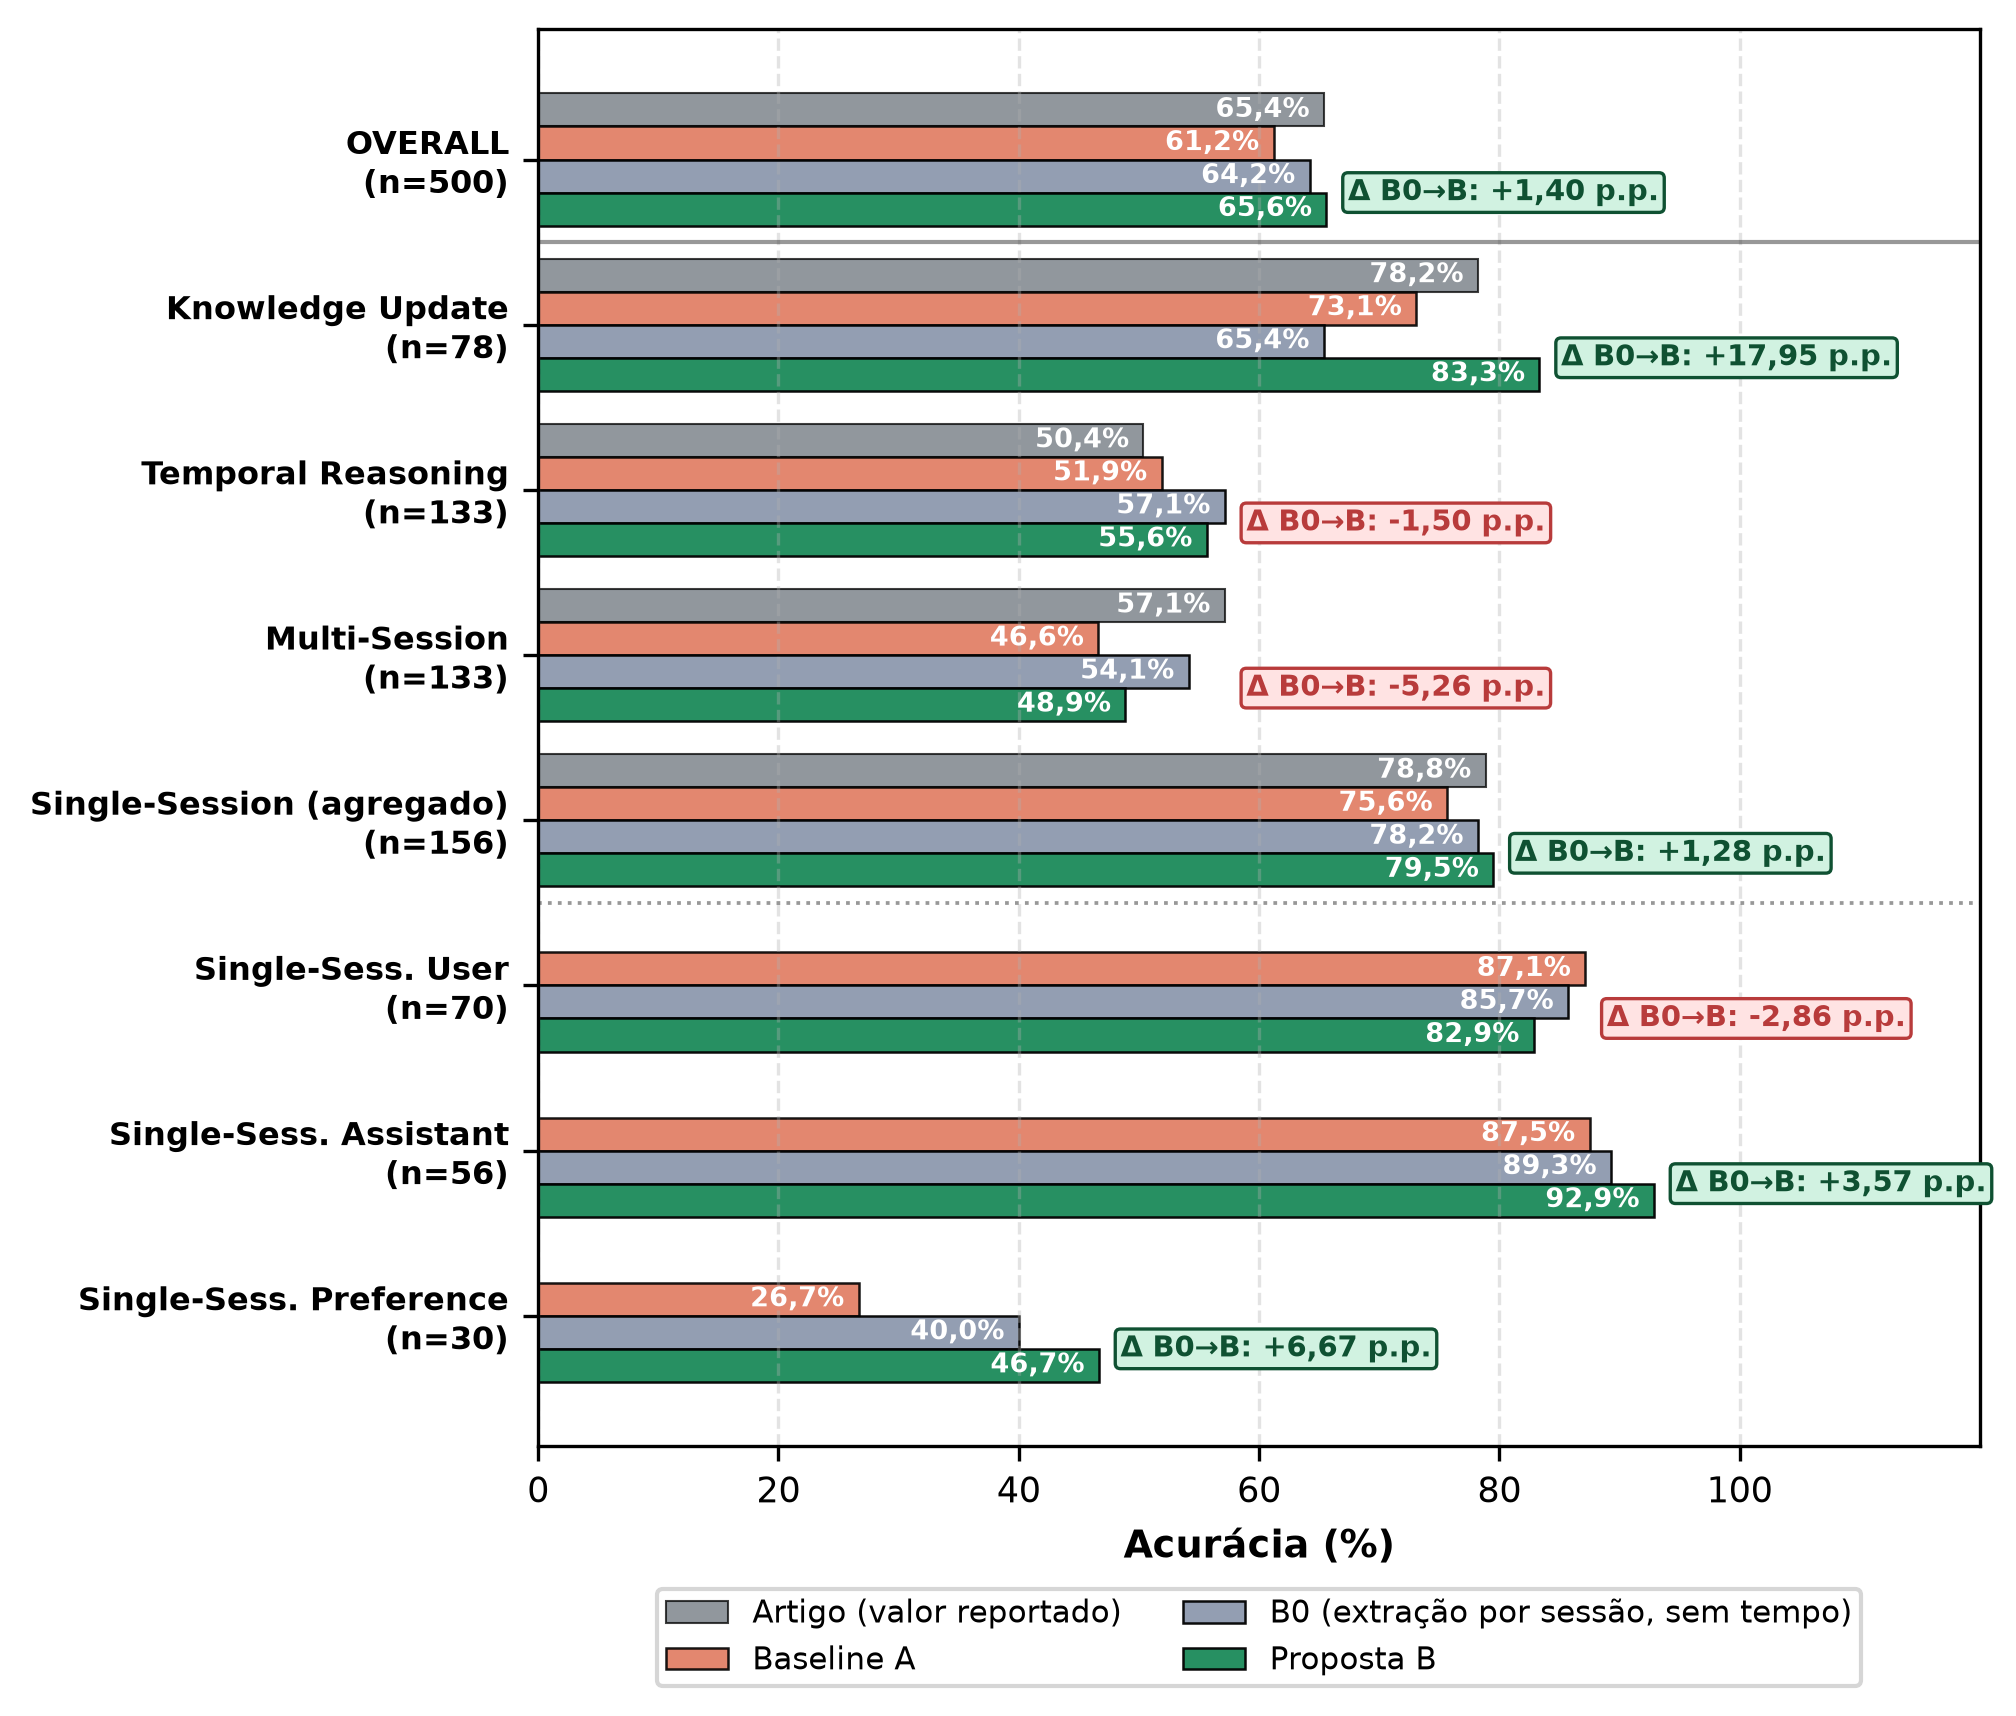

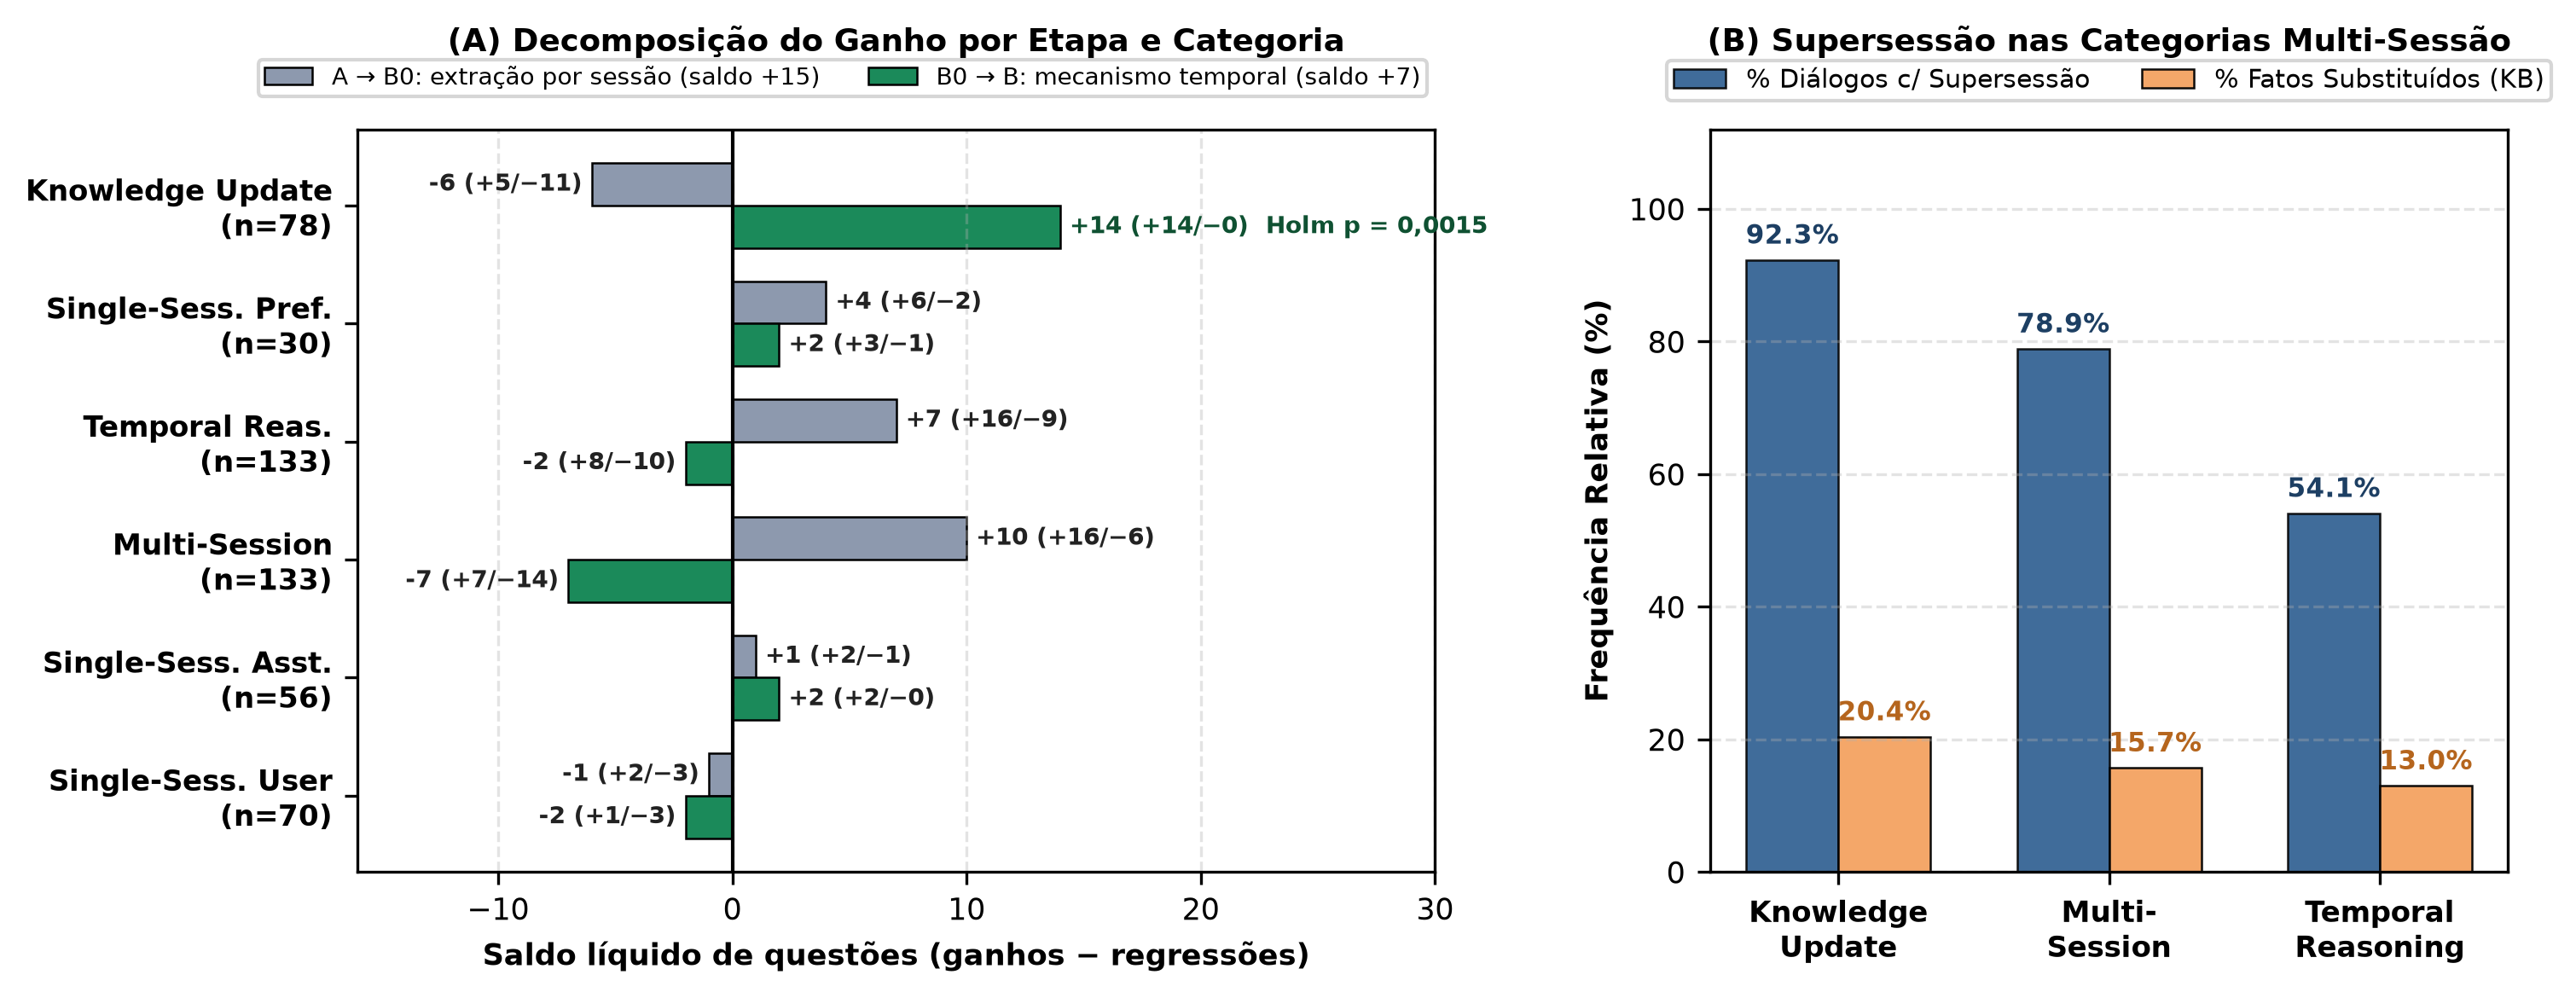

In [11]:
from IPython.display import Image, display as show

subprocess.run([sys.executable, "src/visualization/generate_report_figures.py"], cwd=ROOT, check=True,
               capture_output=True)
for name in ["fig2_baseline_vs_paper.png", "fig3_analise_pareada_ab.png"]:
    show(Image(filename=str(ROOT / "reports" / "figures" / name), width=900))

## Passo 10 — Auditoria do Processo

Reproduz os achados verificáveis da auditoria R05: hiperparâmetros da baseline contra os scripts oficiais e a recodificação entre as duas rodadas de B. O registro completo está em `reports/analysis/R05_auditoria_processo_20261104.md`, e o plano de correção em `docs/plano_resolucao_R05.md`.

In [12]:
out = subprocess.run([sys.executable, "src/analysis/audit_process.py"], cwd=ROOT, capture_output=True, text=True,
                     encoding="utf-8", errors="replace")
print(out.stdout or out.stderr)

1. Hiperparâmetros: Baseline A vs. scripts oficiais
parâmetro                       script oficial    Baseline A  status
HEBBIAN_MAX_FLIPPED                          3             5  DIVERGE
HEBBIAN_KEYWORD_WEIGHT                     0.7           0.5  DIVERGE
HEBBIAN_LEARNING_RATE                     0.02          0.02  ok
HEBBIAN_ACTIVATION_ALPHA                   0.1           0.1  ok
HEBBIAN_SPREADING_THRESHOLD                0.4           0.4  ok
HEBBIAN_DECAY_RATE                       0.995         0.995  ok
HEBBIAN_TAU                                1e7           1e7  ok
HEBBIAN_TOP_K                               15            15  ok
HEBBIAN_SEMANTIC_TOP_K                       5             5  ok

2. Proposta B: rodada d279613 (64,60%) vs. atual (65,60%)
Itens recodificados em 2026-11-03: 100
Posições no dataset: 100–199
Tipos: {'knowledge-update': 78, 'multi-session': 22}
Itens com 0 fatos recuperados na rodada antiga: 99 (todos recodificados: True)
Acertos nesses itens — A:

## Passo 11 — Conclusões

1. **Ganho total:** a Proposta B passou de 61,20% para 65,60% (+22 questões; McNemar bilateral $p = 0{,}023$).
2. **De onde vem o ganho:** a maior parte vem da extração de fatos por sessão (A$\rightarrow$B0: +15). O mecanismo temporal soma +7 no total, sem significância ($p = 0{,}45$).
3. **Onde o mecanismo temporal funciona:** em *Knowledge Update*, B0$\rightarrow$B corrige 14 questões sem nenhuma regressão, todas em diálogos com supersessão; é a única diferença por categoria que resiste à correção de Holm. Sem o mecanismo, a extração mais rica **piora** essa categoria (B0 51/78 contra A 57/78).
4. **Onde atrapalha:** em *Multi-Session*, B0$\rightarrow$B perde 7 questões, quase todas em diálogos com supersessão: eventos repetidos são tratados como substituição e deixam de ser contados.
5. **Leitura da hipótese:** suportada em *Knowledge Update*; não suportada no total. O próximo passo direto é ajustar o classificador para separar estados mutuamente exclusivos (`SUPERSEDES`) de eventos acumulativos (`EXTENDS`).

**Pendências (plano R05):** medir o ruído entre execuções (B'), investigar os 360 grafos semânticos vazios de A, separar o efeito das tags do efeito de $\mathcal{V}$, sensibilidade de $\lambda$ e $\tau$, e avaliação no *LongMemEval-S* completo.